In [ ]:
import pandas
import seaborn
from matplotlib import pyplot
import numpy 
from pandas.plotting import register_matplotlib_converters
from statsmodels.tsa.seasonal import MSTL

from airpollutionforecasting.pipeline import run_pipeline

register_matplotlib_converters()
seaborn.set_style("darkgrid")

2026-11-06 22:47:11.036 | INFO     | airpollutionforecasting.config:<module>:18 - PROJ_ROOT path is: /home/pabito/Desktop/Projects/AirPolutionForecasting


In [2]:
pyplot.rc("figure", figsize=(16, 12))
pyplot.rc("font", size=13)

In [3]:
# run the pipeline to get the location of splitted files
split_files_locations = run_pipeline(stop_step="split")

2026-11-06 22:47:11.050 | INFO     | airpollutionforecasting.pipeline:run_pipeline:28 - Running pipeline until split...
2026-11-06 22:47:11.053 | INFO     | airpollutionforecasting.data.loader:load:20 - Loading the data..
2026-11-06 22:47:11.140 | INFO     | airpollutionforecasting.data.data_validator:validate:149 - Starting data validation...
2026-11-06 22:47:11.140 | INFO     | airpollutionforecasting.data.data_validator:validate:151 - Checking required columns and data types...
2026-11-06 22:47:11.141 | SUCCESS  | airpollutionforecasting.data.data_validator:validate:153 - Column and data type validation passed.
2026-11-06 22:47:11.141 | INFO     | airpollutionforecasting.data.data_validator:validate:155 - Checking configured date range...
2026-11-06 22:47:11.142 | SUCCESS  | airpollutionforecasting.data.data_validator:validate:157 - Date range validation passed.
2026-11-06 22:47:11.143 | INFO     | airpollutionforecasting.data.data_validator:validate:159 - Checking for missing value

In [4]:
# load the training data
data = pandas.read_csv(split_files_locations[0])
data["time"] = pandas.to_datetime(data["time"])

In [5]:
#series on which MSTL should be performed
series = data.set_index("time")["pm_10"]
mstl = MSTL(series, periods=[24, 24 * 365])
res = mstl.fit()

In [6]:
res.seasonal.head()

,seasonal_24,seasonal_8760
time,,
2016-01-01 00:00:00,9.698042,159.378165
2016-01-01 01:00:00,5.457053,136.066761
2016-01-01 02:00:00,9.496373,138.307036
2016-01-01 03:00:00,4.682417,133.191427
2016-01-01 04:00:00,5.232949,136.403897


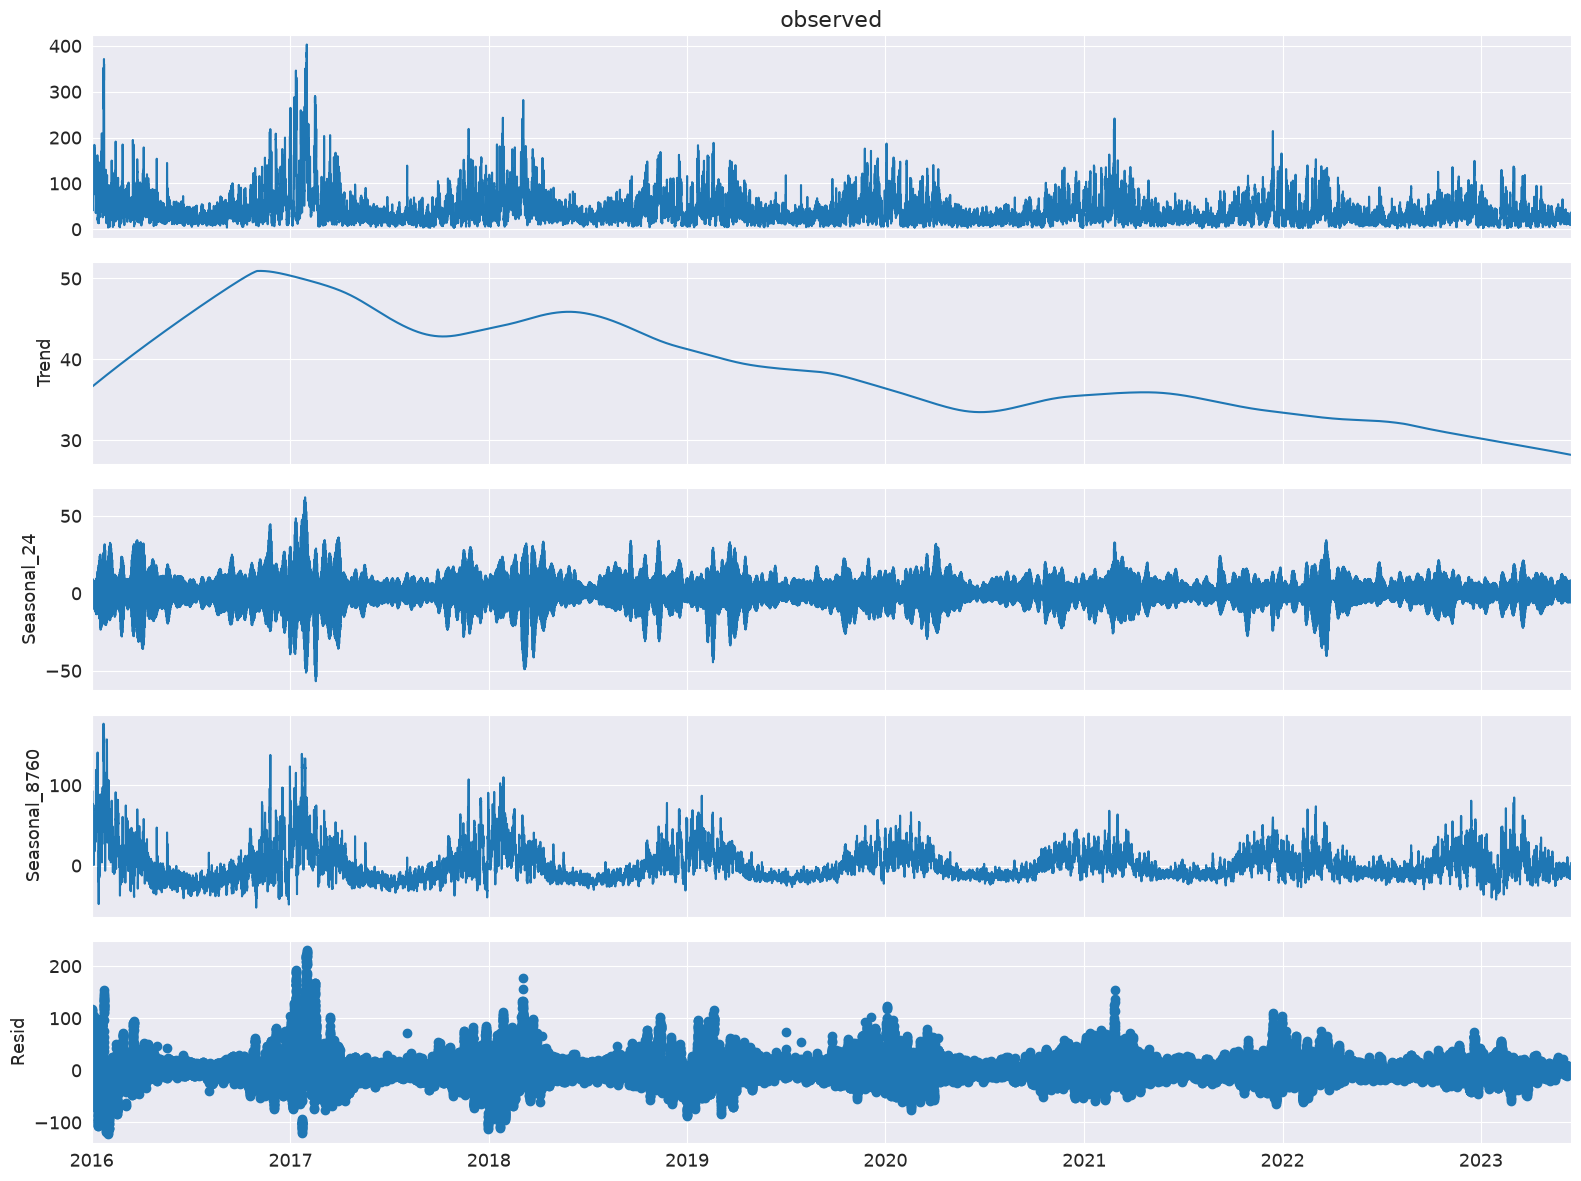

In [7]:
ax = res.plot()

In [ ]:
# try this as well
series_log = numpy.log1p(series)
res = MSTL(series_log, periods=(24, 24 * 7)).fit()

By default, MSTL uses very short seasonal smoothers (window of about 7 for the first period, growing slowly). For the 24h component, that means the daily profile is estimated from only about 7 neighboring days, so it follows day-to-day weather instead of the typical daily shape. Larger windows give a more stable, smoother seasonal pattern. They must be odd:

In [ ]:
res = MSTL(
    series_log,
    periods=(24, 24 * 365),
    windows=(101, 11),          # one per period; larger = smoother/more stable
    iterate=3,
    stl_kwargs={"robust": True},
).fit()

In [ ]:
fig = res.plot()
fig.set_size_inches(14, 10)

res.seasonal.iloc[:24 * 14].plot(figsize=(12, 3))   # two weeks